In [17]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, average_precision_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.semi_supervised import SelfTrainingClassifier

PROJECT_ROOT = Path.cwd().parent
DATA = PROJECT_ROOT / "all_datasets"

In [18]:

SAKURA = {
    "petal": "#F4A7C3",       # soft sakura pink
    "blossom": "#E879A9",     # cherry blossom
    "rose": "#C95D8E",        # rose pink
    "mauve": "#A66C91",       # muted mauve
    "plum": "#6F3F5B",         # deep plum for readable contrast
    "pale": "#FCE8F0",         # pale blossom background
    "grey": "#B9A6B0",         # muted comparison line
}

plt.rcParams.update({
    "figure.facecolor": "#FFFAFC",
    "axes.facecolor": "#FFF7FA",
    "axes.edgecolor": SAKURA["mauve"],
    "axes.labelcolor": SAKURA["plum"],
    "text.color": SAKURA["plum"],
    "xtick.color": SAKURA["plum"],
    "ytick.color": SAKURA["plum"],
    "grid.color": SAKURA["pale"],
    "axes.titleweight": "bold",
    "font.family": "DejaVu Sans",
})


Part A — Isolation Forest fraud ranking

In [19]:
fraud = pd.read_csv(DATA / "credit_card_fraud_dataset.csv")
print(fraud.head())

feature_cols = [
    "amount", "transaction_hour", "foreign_transaction", "location_mismatch",
    "device_trust_score", "velocity_last_24h", "cardholder_age",
]
X = fraud[feature_cols]
y = fraud["is_fraud"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

forest = IsolationForest(n_estimators=300, contamination="auto", random_state=42, n_jobs=-1)
forest.fit(X_train)                                   # no labels passed
anomaly_score = -forest.decision_function(X_test)     # higher = more unusual

   transaction_id  amount  transaction_hour merchant_category  \
0               1   84.47                22       Electronics   
1               2  541.82                 3            Travel   
2               3  237.01                17           Grocery   
3               4  164.33                 4           Grocery   
4               5   30.53                15              Food   

   foreign_transaction  location_mismatch  device_trust_score  \
0                    0                  0                  66   
1                    1                  0                  87   
2                    0                  0                  49   
3                    0                  1                  72   
4                    0                  0                  79   

   velocity_last_24h  cardholder_age  is_fraud  
0                  3              40         0  
1                  1              64         0  
2                  1              61         0  
3                  3  

In [20]:
prevalence = y_test.mean()
ap = average_precision_score(y_test, anomaly_score)
print("fraud prevalence:", round(prevalence, 4))
print("ROC AUC:", round(roc_auc_score(y_test, anomaly_score), 4))
print("average precision:", round(ap, 4), " (", round(ap / prevalence, 1), "x prevalence)")

ranked = X_test.copy()
ranked["fraud_label"] = y_test.to_numpy()
ranked["anomaly_score"] = anomaly_score
ranked = ranked.sort_values("anomaly_score", ascending=False)
review_budget = 100
top_k_precision = ranked.head(review_budget)["fraud_label"].mean()
print(f"fraud found in the top {review_budget}: {top_k_precision:.0%}")
print(ranked[["fraud_label", "anomaly_score", "amount"]].head(10))

fraud prevalence: 0.015
ROC AUC: 0.9518
average precision: 0.2249  ( 15.0 x prevalence)
fraud found in the top 100: 20%
      fraud_label  anomaly_score  amount
6394            0       0.212892  840.89
5883            0       0.168657  978.56
1623            1       0.166446  569.02
522             0       0.165520  630.67
5536            1       0.163377   28.31
9073            0       0.158442  131.05
4642            0       0.155478  351.99
645             1       0.155063  398.17
7166            0       0.154388  353.58
7698            0       0.152780   75.88


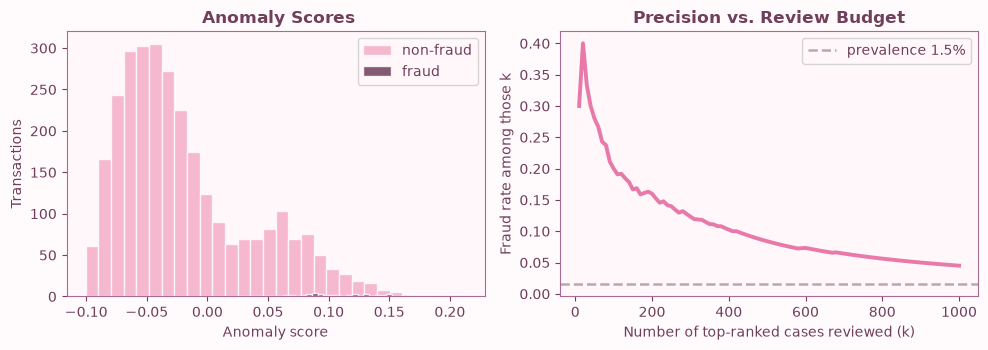

In [21]:
hits = ranked["fraud_label"].to_numpy()
k_values = np.arange(10, 1001, 10)
precision_at_k = [hits[:k].mean() for k in k_values]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(anomaly_score[y_test.to_numpy() == 0], bins=30, alpha=0.78, color=SAKURA["petal"], edgecolor="white", label="non-fraud")
axes[0].hist(anomaly_score[y_test.to_numpy() == 1], bins=30, alpha=0.85, color=SAKURA["plum"], edgecolor="white", label="fraud")
axes[0].set_xlabel("Anomaly score")
axes[0].set_ylabel("Transactions")
axes[0].set_title(" Anomaly Scores")
axes[0].legend()
axes[1].plot(k_values, precision_at_k, color=SAKURA["blossom"], linewidth=2.8)
axes[1].axhline(prevalence, linestyle="--", linewidth=1.8, color=SAKURA["grey"], label=f"prevalence {prevalence:.1%}")
axes[1].set_xlabel("Number of top-ranked cases reviewed (k)")
axes[1].set_ylabel("Fraud rate among those k")
axes[1].set_title("Precision vs. Review Budget")
axes[1].legend()
plt.tight_layout()
plt.show()

Interpretation:
- Fraud makes up 1.5% of the test transactions (45 of 3,000)
- Isolation Forest reaches a ROC AUC of 0.952, which means it ranks most frauds above most normal transactions
- The average precision is only 0.225 (This is 15 times better than random guessing)
- Among the top 100 alerts, only 20% are fraud, so 80 of the 100 reviews will be false alarms because normal transactions greatly outnumber frauds, so even a small share of unusual normal transactions fills the top of the list.
- The histogram shows this overlap, and the precision curve falls towards the 1.5% prevalence line as the review budget grows.
- A high ROC AUC alone will therefore overstate how useful the model is, and precision at the real review budget is the more honest measure.


Part B — Self-training and active learning with few labels

In [22]:
rng = np.random.default_rng(42)

cancer = pd.read_csv(DATA / "breast_cancer_dataset.csv")
X_c = cancer.drop(columns=["id", "diagnosis", "Unnamed: 32"], errors="ignore")
y_c = (cancer["diagnosis"] == "M").astype(int).to_numpy()

X_dev, Xc_test, y_dev, yc_test = train_test_split(
    X_c, y_c, test_size=0.25, random_state=42, stratify=y_c
)
X_pool, X_val, y_pool, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=7, stratify=y_dev
)
X_pool = X_pool.reset_index(drop=True)
y_pool = np.asarray(y_pool)
print("pool:", len(X_pool), " validation:", len(X_val), " test:", len(Xc_test))

def make_model():
    return Pipeline([
        ("scale", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000)),
    ])

pool: 319  validation: 107  test: 143


In [23]:
y_partial = y_pool.copy()
y_partial[rng.random(len(y_partial)) < 0.70] = -1
print("labels kept:", int((y_partial != -1).sum()), "of", len(y_partial))

semi = Pipeline([
    ("scale", StandardScaler()),
    ("model", SelfTrainingClassifier(LogisticRegression(max_iter=2000), threshold=0.90)),
])
semi.fit(X_pool, y_partial)
print("self-training validation accuracy:",
      round(accuracy_score(y_val, semi.predict(X_val)), 3))

labels kept: 89 of 319
self-training validation accuracy: 0.963


In [24]:
class0 = np.where(y_pool == 0)[0]
class1 = np.where(y_pool == 1)[0]
initial = np.concatenate([rng.choice(class0, 20, replace=False),
                          rng.choice(class1, 20, replace=False)])
active_labeled = set(initial.tolist())
random_labeled = set(initial.tolist())
rng_random = np.random.default_rng(123)

query_batch, rounds = 15, 8
label_counts, active_scores, random_scores = [], [], []

for round_no in range(rounds):
    active_idx, random_idx = sorted(active_labeled), sorted(random_labeled)
    active = make_model().fit(X_pool.iloc[active_idx], y_pool[active_idx])
    random_model = make_model().fit(X_pool.iloc[random_idx], y_pool[random_idx])

    label_counts.append(len(active_labeled))
    active_scores.append(accuracy_score(y_val, active.predict(X_val)))
    random_scores.append(accuracy_score(y_val, random_model.predict(X_val)))
    print(f"round {round_no + 1}: labels={label_counts[-1]:3d} "
          f"uncertainty={active_scores[-1]:.3f} random={random_scores[-1]:.3f}")
    if round_no == rounds - 1:
        break

    unlabeled = np.array([i for i in range(len(X_pool)) if i not in active_labeled])
    uncertainty = np.abs(active.predict_proba(X_pool.iloc[unlabeled])[:, 1] - 0.5)
    active_labeled.update(unlabeled[np.argsort(uncertainty)[:query_batch]].tolist())

    unlabeled = np.array([i for i in range(len(X_pool)) if i not in random_labeled])
    random_labeled.update(rng_random.choice(unlabeled, query_batch, replace=False).tolist())

round 1: labels= 40 uncertainty=0.944 random=0.944
round 2: labels= 55 uncertainty=0.925 random=0.953
round 3: labels= 70 uncertainty=0.981 random=0.963
round 4: labels= 85 uncertainty=0.953 random=0.963
round 5: labels=100 uncertainty=0.953 random=0.953
round 6: labels=115 uncertainty=0.953 random=0.953
round 7: labels=130 uncertainty=0.953 random=0.963
round 8: labels=145 uncertainty=0.953 random=0.963


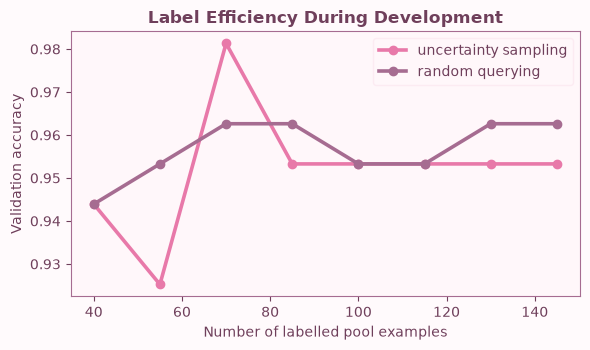

In [25]:
plt.figure(figsize=(6, 3.6))
plt.plot(label_counts, active_scores, marker="o", markersize=6, linewidth=2.6, color=SAKURA["blossom"], label="uncertainty sampling")
plt.plot(label_counts, random_scores, marker="o", markersize=6, linewidth=2.6, color=SAKURA["mauve"], label="random querying")
plt.xlabel("Number of labelled pool examples")
plt.ylabel("Validation accuracy")
plt.title("Label Efficiency During Development")
plt.legend(frameon=True, facecolor="#FFF7FA", edgecolor=SAKURA["pale"])
plt.tight_layout()
plt.show()

Both policies are finished, so the sealed test set is opened once for each

In [26]:
active_idx, random_idx = sorted(active_labeled), sorted(random_labeled)
active_final = make_model().fit(X_pool.iloc[active_idx], y_pool[active_idx])
random_final = make_model().fit(X_pool.iloc[random_idx], y_pool[random_idx])
print("final test accuracy, uncertainty sampling:",
      round(accuracy_score(yc_test, active_final.predict(Xc_test)), 3))
print("final test accuracy, random querying:    ",
      round(accuracy_score(yc_test, random_final.predict(Xc_test)), 3))

final test accuracy, uncertainty sampling: 0.972
final test accuracy, random querying:     0.972


Interpretation:

- The pool has 319 rows, the validation set has 107 rows and the sealed test set has 143 rows.
Self-training keeps 89 of the 319 pool labels (about 28%) and reaches 0.963 validation accuracy. This is as good as the active learning models that use more labels, so the confident pseudo-labels helped here. The risk is that wrong pseudo-labels are added with high confidence and then reinforce the model's mistakes.

- In the active learning loop, both policies start at 0.944 with 40 labels. Uncertainty sampling reaches 0.981 at 70 labels but then settles at 0.953, while random querying ends at 0.963. One validation case is worth about 0.009 accuracy, so these differences are only one or two patients. On the sealed test set, both final models reach the same accuracy of 0.972. With 20 starting labels per class, uncertainty sampling shows no clear gain over random querying, because the logistic regression model already learns this task well from a small number of labels.


TRY IT YOURSELF SECTION

1. Fraud precision at review budgets of 50 and 300

In [27]:
for budget in [50, 100, 300]:
    top = ranked.head(budget)["fraud_label"]
    print(f"top {budget:3d}: precision = {top.mean():.0%}  "
          f"frauds caught = {int(top.sum())} of {int(y_test.sum())} "
          f"(recall {top.sum() / y_test.sum():.0%})")

top  50: precision = 28%  frauds caught = 14 of 45 (recall 31%)
top 100: precision = 20%  frauds caught = 20 of 45 (recall 44%)
top 300: precision = 12%  frauds caught = 37 of 45 (recall 82%)


2. Uncertainty sampling starting from ten labels per class

- The loop is the same as above, but it is wrapped in a function so that the starting labels can change. 
- Only the validation set is used here, so the sealed test set stays unopened.

In [28]:
def run_active_vs_random(n_per_class, seed=42, random_seed=123, query_batch=15, rounds=8):
    rng_start = np.random.default_rng(seed)
    rng_rand = np.random.default_rng(random_seed)
    start = np.concatenate([rng_start.choice(class0, n_per_class, replace=False),
                            rng_start.choice(class1, n_per_class, replace=False)])
    act, rnd = set(start.tolist()), set(start.tolist())
    counts, act_acc, rnd_acc = [], [], []
    for round_no in range(rounds):
        a_idx, r_idx = sorted(act), sorted(rnd)
        a_model = make_model().fit(X_pool.iloc[a_idx], y_pool[a_idx])
        r_model = make_model().fit(X_pool.iloc[r_idx], y_pool[r_idx])
        counts.append(len(act))
        act_acc.append(accuracy_score(y_val, a_model.predict(X_val)))
        rnd_acc.append(accuracy_score(y_val, r_model.predict(X_val)))
        if round_no == rounds - 1:
            break
        unl = np.array([i for i in range(len(X_pool)) if i not in act])
        unc = np.abs(a_model.predict_proba(X_pool.iloc[unl])[:, 1] - 0.5)
        act.update(unl[np.argsort(unc)[:query_batch]].tolist())
        unl = np.array([i for i in range(len(X_pool)) if i not in rnd])
        rnd.update(rng_rand.choice(unl, query_batch, replace=False).tolist())
    return np.array(counts), np.array(act_acc), np.array(rnd_acc)

counts10, act10, rnd10 = run_active_vs_random(n_per_class=10)
for c, a, r in zip(counts10, act10, rnd10):
    print(f"labels={c:3d} uncertainty={a:.3f} random={r:.3f}")

labels= 20 uncertainty=0.935 random=0.935
labels= 35 uncertainty=0.944 random=0.944
labels= 50 uncertainty=0.963 random=0.963
labels= 65 uncertainty=0.953 random=0.953
labels= 80 uncertainty=0.953 random=0.963
labels= 95 uncertainty=0.953 random=0.944
labels=110 uncertainty=0.953 random=0.953
labels=125 uncertainty=0.953 random=0.944



start = 10 labels per class (mean of 20 runs)
  labels= 20 uncertainty=0.918 random=0.918 gap=+0.000
  labels= 35 uncertainty=0.945 random=0.936 gap=+0.009
  labels= 50 uncertainty=0.962 random=0.943 gap=+0.019
  labels= 65 uncertainty=0.957 random=0.944 gap=+0.014
  labels= 80 uncertainty=0.954 random=0.943 gap=+0.011
  labels= 95 uncertainty=0.954 random=0.950 gap=+0.004
  labels=110 uncertainty=0.954 random=0.951 gap=+0.003
  labels=125 uncertainty=0.954 random=0.954 gap=-0.000

start = 20 labels per class (mean of 20 runs)
  labels= 40 uncertainty=0.945 random=0.945 gap=+0.000
  labels= 55 uncertainty=0.957 random=0.950 gap=+0.007
  labels= 70 uncertainty=0.960 random=0.950 gap=+0.011
  labels= 85 uncertainty=0.958 random=0.950 gap=+0.008
  labels=100 uncertainty=0.958 random=0.949 gap=+0.009
  labels=115 uncertainty=0.957 random=0.950 gap=+0.006
  labels=130 uncertainty=0.956 random=0.951 gap=+0.005
  labels=145 uncertainty=0.957 random=0.951 gap=+0.006


C:\Users\VICTUS\AppData\Local\Temp\ipykernel_24080\957638026.py:22: UserWarning: Glyph 127800 (\N{CHERRY BLOSSOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
c:\Users\VICTUS\anaconda3\envs\venv2\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 127800 (\N{CHERRY BLOSSOM}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


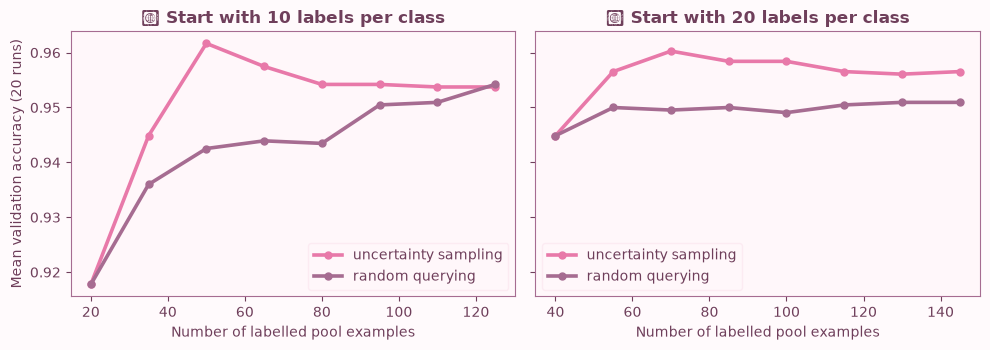

In [29]:
n_repeats = 20
results = {}
for n_per_class in [10, 20]:
    runs = [run_active_vs_random(n_per_class, seed=s, random_seed=1000 + s) for s in range(n_repeats)]
    counts = runs[0][0]
    act_mean = np.mean([r[1] for r in runs], axis=0)
    rnd_mean = np.mean([r[2] for r in runs], axis=0)
    results[n_per_class] = (counts, act_mean, rnd_mean)
    print(f"\nstart = {n_per_class} labels per class (mean of {n_repeats} runs)")
    for c, a, r in zip(counts, act_mean, rnd_mean):
        print(f"  labels={c:3d} uncertainty={a:.3f} random={r:.3f} gap={a - r:+.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, n_per_class in zip(axes, [10, 20]):
    counts, act_mean, rnd_mean = results[n_per_class]
    ax.plot(counts, act_mean, marker="o", markersize=5, linewidth=2.6, color=SAKURA["blossom"], label="uncertainty sampling")
    ax.plot(counts, rnd_mean, marker="o", markersize=5, linewidth=2.6, color=SAKURA["mauve"], label="random querying")
    ax.set_xlabel("Number of labelled pool examples")
    ax.set_title(f"🌸 Start with {n_per_class} labels per class")
    ax.legend(frameon=True, facecolor="#FFF7FA", edgecolor=SAKURA["pale"])
axes[0].set_ylabel(f"Mean validation accuracy ({n_repeats} runs)")
plt.tight_layout()
plt.show()

Explaination:

With ten labels per class and the original random seed, uncertainty sampling and random querying give almost the same validation accuracy in every round. One run is not enough to judge, so the comparison was repeated 20 times with different starting labels.

On average, uncertainty sampling now shows a small early gain. With 10 labels per class, it is ahead by 0.019 at 50 labels and by 0.014 at 65 labels, and the gap disappears by 125 labels. With 20 labels per class, the gain is smaller (at most 0.011). Uncertainty sampling therefore helps most when the starting label budget is very small, because each chosen example near the decision boundary corrects the model more than a random example. Once the model has enough labels, both policies reach the same accuracy. The gain is still only about one or two validation cases, so it is useful but modest on this dataset.